# 03 · LightGBM challengers + MLflow experiment tracking

We now build gradient-boosted challengers using **the same likelihoods as the GLMs** (so they are directly comparable):

| Model | LightGBM objective | Target | Weight |
|---|---|---|---|
| Frequency | `poisson` | claims / exposure | exposure |
| Severity | `gamma` | average cost per claim (claims only) | claim count |
| Pure premium (direct) | `tweedie` (p = 1.5) | loss / exposure | exposure |

Pricing-specific touches:
* **Monotonic constraint** on `BonusMalus` (a worse claims record can never *reduce* the predicted frequency) — GBMs can otherwise learn noisy, indefensible shapes.
* **Early stopping** on a held-out validation set; the **test set is touched once** at the end.
* **Optuna** for light hyper-parameter search (sized for an 8 GB laptop). Set `N_TRIALS_FREQ` / `N_TRIALS_SEV` env vars to change it.
* Every run is logged to **MLflow** (`mlflow ui` from the project root to browse).

In [1]:
%load_ext autoreload
%autoreload 2
import os
import warnings

warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import mlflow
import optuna
import pandas as pd

from motor_pricing.config import MLFLOW_EXPERIMENT, MLFLOW_URI, MODELS_DIR, PROCESSED_DIR, SEED
from motor_pricing.data import load_data, split_data
from motor_pricing.evaluation import mean_deviance, null_rates, scorecard
from motor_pricing.features import FEATURES, learn_categories
from motor_pricing.models import (
    FREQ_DEFAULTS, SEV_DEFAULTS, TWEEDIE_DEFAULTS, fit_lgbm,
    freq_xyw, prepare, sev_xyw, tweedie_xyw,
)
from motor_pricing.scoring import build_artifact

N_TRIALS_FREQ = int(os.environ.get("N_TRIALS_FREQ", 30))
N_TRIALS_SEV = int(os.environ.get("N_TRIALS_SEV", 20))
optuna.logging.set_verbosity(optuna.logging.WARNING)
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(MLFLOW_EXPERIMENT)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.4f}".format)

2026/11/02 10:00:42 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/02 10:00:42 INFO mlflow.store.db.utils: Updating database tables
2026/11/02 10:00:43 INFO mlflow.tracking.fluent: Experiment with name 'motor-pricing' does not exist. Creating a new experiment.


In [2]:
df = load_data()
train, valid, test = split_data(df)
categories = learn_categories(train)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)


def log_run(name, params, metrics, artifact_path=None):
    """Log one model to MLflow (lists such as monotone_constraints are stringified)."""
    with mlflow.start_run(run_name=name):
        mlflow.log_params({k: str(v) for k, v in params.items() if k not in ("n_jobs", "verbose")})
        mlflow.log_metrics(metrics)
        if artifact_path:
            mlflow.log_artifact(str(artifact_path))

## 1. Frequency model (Poisson objective)
First a sensible default configuration, then Optuna to tune it.

In [3]:
Xtr, ytr, wtr = freq_xyw(train, categories)
Xva, yva, wva = freq_xyw(valid, categories)

default_model = fit_lgbm(Xtr, ytr, wtr, Xva, yva, wva, FREQ_DEFAULTS)
default_dev = mean_deviance("poisson", yva, default_model.predict(Xva), wva)
print(f"default config → validation Poisson deviance {default_dev:.5f} ({default_model.best_iteration_} trees)")


def objective(trial):
    params = {
        **FREQ_DEFAULTS,
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 8, 64, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 50, 1000, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-2, 50, log=True),
    }
    model = fit_lgbm(Xtr, ytr, wtr, Xva, yva, wva, params)
    return mean_deviance("poisson", yva, model.predict(Xva), wva)


study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=N_TRIALS_FREQ)
print(f"best validation deviance after {len(study.trials)} trials: {study.best_value:.5f}")
study.best_params

default config → validation Poisson deviance 0.45240 (256 trees)
best validation deviance after 30 trials: 0.45228


{'learning_rate': 0.028935990541186854,
 'num_leaves': 28,
 'min_child_samples': 579,
 'colsample_bytree': 0.7183609462931887,
 'reg_lambda': 0.04904488350744817}

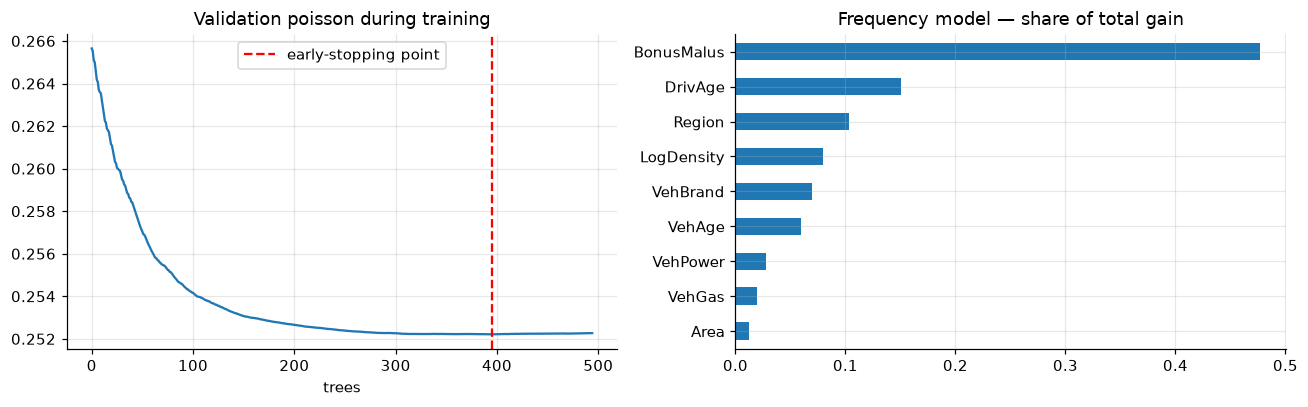

In [4]:
freq_params = {**FREQ_DEFAULTS, **study.best_params}
freq_model = fit_lgbm(Xtr, ytr, wtr, Xva, yva, wva, freq_params)
freq_valid_dev = mean_deviance("poisson", yva, freq_model.predict(Xva), wva)

evals = freq_model.evals_result_["valid_0"]
metric = next(iter(evals))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(evals[metric])
axes[0].axvline(freq_model.best_iteration_, color="r", ls="--", label="early-stopping point")
axes[0].set(title=f"Validation {metric} during training", xlabel="trees")
axes[0].legend()
imp = pd.Series(freq_model.booster_.feature_importance("gain"), index=FEATURES).sort_values()
(imp / imp.sum()).plot.barh(ax=axes[1], title="Frequency model — share of total gain")
plt.tight_layout()

## 2. Severity model (Gamma objective, claims only)
Only a few percent of policies have claims, so there is little data → small trees, strong regularisation, fewer trials.

In [5]:
Str, sytr, swtr = sev_xyw(train, categories)
Sva, syva, swva = sev_xyw(valid, categories)
print(f"severity training rows: {len(Str):,} | validation rows: {len(Sva):,}")


def sev_objective(trial):
    params = {
        **SEV_DEFAULTS,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 4, 32, log=True),
        "min_child_samples": trial.suggest_int("min_child_samples", 30, 400, log=True),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-1, 100, log=True),
    }
    model = fit_lgbm(Str, sytr, swtr, Sva, syva, swva, params)
    return mean_deviance("gamma", syva, model.predict(Sva), swva)


sev_study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEED))
sev_study.optimize(sev_objective, n_trials=N_TRIALS_SEV)
sev_params = {**SEV_DEFAULTS, **sev_study.best_params}
sev_model = fit_lgbm(Str, sytr, swtr, Sva, syva, swva, sev_params)
sev_valid_dev = mean_deviance("gamma", syva, sev_model.predict(Sva), swva)
print(f"best validation Gamma deviance: {sev_valid_dev:.5f} ({sev_model.best_iteration_} trees)")
sev_study.best_params

severity training rows: 17,460 | validation rows: 3,742
best validation Gamma deviance: 1.36862 (33 trees)


{'learning_rate': 0.04050837781329675,
 'num_leaves': 5,
 'min_child_samples': 35,
 'colsample_bytree': 0.9744427686266666,
 'reg_lambda': 78.8671412999049}

## 3. Direct pure-premium model (Tweedie)
One model on loss ÷ exposure. Tweedie with power between 1 and 2 is a compound Poisson–Gamma distribution — exactly the
claims-count × claim-size process. We keep the power fixed at 1.5 (deviances for different powers are *not comparable*, so it can't be picked by validation deviance).

In [6]:
Ttr, tytr, twtr = tweedie_xyw(train, categories)
Tva, tyva, twva = tweedie_xyw(valid, categories)
tweedie_model = fit_lgbm(Ttr, tytr, twtr, Tva, tyva, twva, TWEEDIE_DEFAULTS)
print(f"Tweedie model: {tweedie_model.best_iteration_} trees")

Tweedie model: 48 trees


## 4. One-off evaluation on the untouched test set

In [7]:
Xte = prepare(test, categories)
gbm_pred = pd.DataFrame({"frequency": freq_model.predict(Xte), "severity": sev_model.predict(Xte)})
gbm_pred["pure_premium"] = gbm_pred["frequency"] * gbm_pred["severity"]
tweedie_pred = pd.DataFrame({"pure_premium": tweedie_model.predict(Xte)})

preds = {"LightGBM freq × sev": gbm_pred, "LightGBM Tweedie": tweedie_pred}
glm_path = PROCESSED_DIR / "glm_test_predictions.parquet"
if glm_path.exists():
    glm_pred = pd.read_parquet(glm_path).set_index("IDpol").loc[test["IDpol"]].reset_index(drop=True)
    preds = {"Poisson×Gamma GLM": glm_pred[["frequency", "severity", "pure_premium"]], **preds}
else:
    print("(run notebook 02 first to include the GLM in this comparison)")

card = scorecard(test, preds, null_rates(train))
card

,freq_poisson_dev,sev_gamma_dev,pp_tweedie_dev,gini,gini_vs_best_possible
null (portfolio average),0.4763,1.4122,78.9311,0.0118,0.0120
Poisson×Gamma GLM,0.4559,1.4182,75.1845,0.3129,0.3183
LightGBM freq × sev,0.4495,1.4060,73.9088,0.3630,0.3692
LightGBM Tweedie,NaN,NaN,74.5658,0.3344,0.3401


*Lower deviance and higher Gini are better.* Don't over-read small differences: on 100k test policies with ~7% claim frequency the noise is material —
notebook 04 adds lift/double-lift charts that show **where** the models disagree and who is right.

## 5. Persist models, predictions and the scoring artifact + log to MLflow

In [8]:
artifact = build_artifact(
    freq_model, sev_model, categories,
    metrics={"valid_freq_poisson_deviance": freq_valid_dev, "valid_sev_gamma_deviance": sev_valid_dev},
)
artifact_path = MODELS_DIR / "pricing_artifact.joblib"
joblib.dump(artifact, artifact_path)
joblib.dump(tweedie_model, MODELS_DIR / "tweedie_model.joblib")

pd.concat([gbm_pred.add_prefix("gbm_"), tweedie_pred.add_prefix("tweedie_")], axis=1).assign(
    IDpol=test["IDpol"].to_numpy()
).to_parquet(PROCESSED_DIR / "gbm_test_predictions.parquet", index=False)

log_run("lgbm_frequency_poisson", freq_params,
        {"valid_deviance": freq_valid_dev, "test_deviance": card.loc["LightGBM freq × sev", "freq_poisson_dev"]},
        artifact_path)
log_run("lgbm_severity_gamma", sev_params,
        {"valid_deviance": sev_valid_dev, "test_deviance": card.loc["LightGBM freq × sev", "sev_gamma_dev"]})
log_run("lgbm_tweedie_pure_premium", TWEEDIE_DEFAULTS,
        {"test_deviance": card.loc["LightGBM Tweedie", "pp_tweedie_dev"],
         "test_gini": card.loc["LightGBM Tweedie", "gini"]})
print("models saved to", MODELS_DIR, "| MLflow experiment:", MLFLOW_EXPERIMENT)
print("browse runs with:  uv run mlflow ui --backend-store-uri", MLFLOW_URI)

models saved to models | MLflow experiment: motor-pricing
browse runs with:  uv run mlflow ui --backend-store-uri sqlite:///mlflow.db


## Takeaways
* Same objectives as the GLMs ⇒ an apples-to-apples comparison.
* `BonusMalus` is monotone-constrained: a deliberate trade of a little accuracy for a defensible pricing structure.
* `models/pricing_artifact.joblib` now powers the FastAPI service (`make api`).
* Next: **`04_evaluation_and_explainability.ipynb`** — lift charts, double-lift, calibration, SHAP and a governance note.